# Offline RL: why naive Q-learning lies, and three ways to stop it

**Code:** [`envs/datasets.py`](../envs/datasets.py) · [`algos/offline_q.py`](../algos/offline_q.py) · [`algos/cql_tabular.py`](../algos/cql_tabular.py) · [`algos/bcq_tabular.py`](../algos/bcq_tabular.py) · [`algos/iql_tabular.py`](../algos/iql_tabular.py) · [`algos/offline_to_online.py`](../algos/offline_to_online.py)
**Papers:** Levine et al. 2020 ([PDF](../papers/imitation-offline/levine-2020-offline-rl-survey.pdf)), Fujimoto et al. 2019 ([PDF](../papers/imitation-offline/fujimoto-2019-bcq.pdf)), Kumar et al. 2020 ([PDF](../papers/imitation-offline/kumar-2020-cql.pdf)), Kostrikov et al. 2021 ([PDF](../papers/imitation-offline/kostrikov-2021-iql.pdf)) ·
**Notes:** [`papers/imitation-offline/notes.md`](../papers/imitation-offline/notes.md)

You get a fixed log of transitions **with rewards**, and you may not touch the environment.

What you will see:

1. Naive offline Q-learning believing it will score about −2 and scoring about −99, with no bug in the code.
2. CQL, BCQ and IQL: three mechanisms, each with one dial that runs from "trust the Q function" to "copy the data".
3. All methods on four dataset qualities. On expert data behaviour cloning is as good as anything; on mixed data it is not.
4. Offline pretraining followed by online fine-tuning, and what happens at the handover.

Every return is exact (`env.policy_return`), so no number here has sampling noise.
Runs on CPU. Run from the repo root or with the repo installed (`pip install -e .`).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from algos import bcq_tabular, cql_tabular, iql_tabular, offline_q, offline_to_online
from envs import datasets
from envs.racetrack import Racetrack

GAMMA = 0.99
plt.rcParams["figure.dpi"] = 110
env = Racetrack()
optimal = env.optimal_return(GAMMA)

## 0. The problem and the data

Same racetrack as the imitation notebook: 7,126 states, 9 accelerations, −1 per step, exact optimum about −6.
The data is a log of 20,000 transitions from a **behaviour policy** of one of four qualities ([`envs/datasets.py:98-121`](../envs/datasets.py)):

| quality | behaviour policy |
| --- | --- |
| `expert` | optimal action 95%, uniform 5% |
| `medium` | optimal action 40%, uniform 60% |
| `random` | uniform |
| `mixed` | optimal action 15%, uniform 85% |

Each row of the log has five columns:

| column | meaning |
| --- | --- |
| `states` | state index the action was taken from |
| `actions` | action index, 0–8 |
| `rewards` | always −1 on this track |
| `next_states` | where the car ended up |
| `terminated` | `True` if that step crossed the finish line |

**Coverage** is the fraction of (state, action) pairs the log contains at least once. Everything outside it is never updated by anything.

In [2]:
logs = {q: datasets.build(env, q, n_transitions=20_000, gamma=GAMMA, seed=0) for q in datasets.QUALITIES}
behaviour = {q: env.policy_return(datasets.behaviour_policy_for(env, q, GAMMA), GAMMA) for q in datasets.QUALITIES}

d = logs["medium"]
print("first 8 rows of the medium log:\n")
print(f"{'states':>7} {'actions':>8} {'rewards':>8} {'next_states':>12} {'terminated':>11}")
for i in range(8):
    print(f"{d.states[i]:>7} {d.actions[i]:>8} {d.rewards[i]:>8.1f} {d.next_states[i]:>12} {str(d.terminated[i]):>11}")

print(f"\nexact optimum {optimal:.2f}\n")
print(f"{'quality':>8} {'coverage':>9} {'episodes ended':>15} {'behaviour return':>17}")
for q, log in logs.items():
    print(f"{q:>8} {log.coverage():>9.3f} {int(log.terminated.sum()):>15,} {behaviour[q]:>17.2f}")

first 8 rows of the medium log:

 states  actions  rewards  next_states  terminated
   6750        4     -1.0         6750       False
   6750        0     -1.0         6750       False
   6750        0     -1.0         6750       False
   6750        6     -1.0         6750       False
   6750        7     -1.0         6280       False
   6280        8     -1.0         5361       False
   5361        8     -1.0         3992       False
   3992        5     -1.0         2617       False

exact optimum -6.54

 quality  coverage  episodes ended  behaviour return
  expert     0.012           2,804             -6.88
  medium     0.062           1,361            -13.50
  random     0.053             499            -32.05
   mixed     0.067             810            -21.59


Where each log actually goes: transitions per track cell, on a log scale. Grey cells never appear in the log.
The expert log is a narrow line; the random log fills the bottom of the track and rarely reaches the finish.

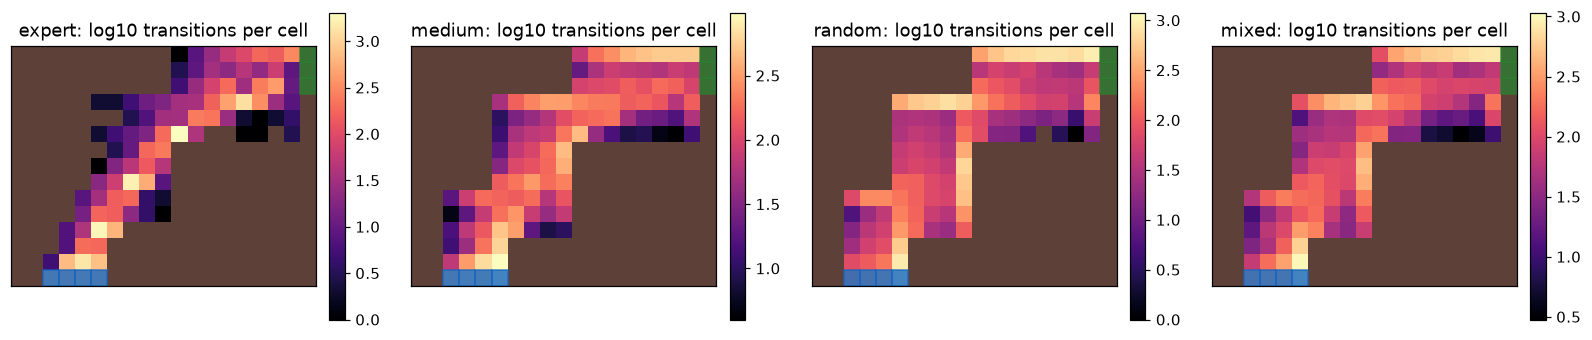

In [3]:
from diagnostics.plots import racetrack_figure

fig, axs = plt.subplots(1, 4, figsize=(18, 5))
for ax, (q, log) in zip(axs, logs.items()):
    per_cell = np.full((env.rows, env.cols), np.nan)
    for s in log.states:
        cell, _, _ = env.decode(int(s))
        per_cell[cell] = (0 if np.isnan(per_cell[cell]) else per_cell[cell]) + 1
    racetrack_figure(env, ax, cell_values=np.log10(per_cell), cmap="magma", title=f"{q}: log10 transitions per cell")
plt.show()

## 1. Four backups, one line apart

Every method here is fitted Q iteration over the log. They differ only in the target.

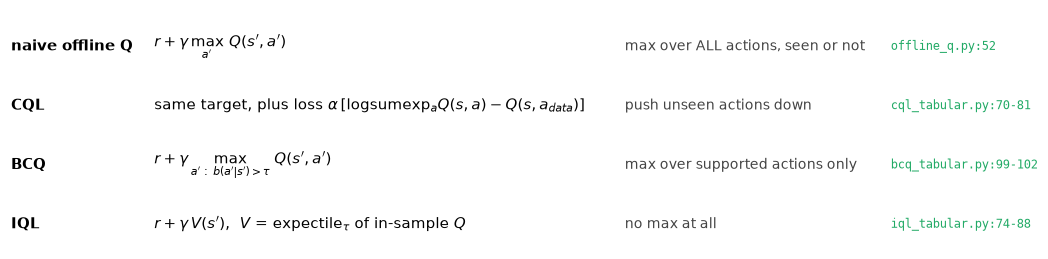

In [4]:
rows = [("naive offline Q", r"$r + \gamma\,\max_{a'}\ Q(s',a')$", "max over ALL actions, seen or not", "offline_q.py:52"),
        ("CQL", r"same target, plus loss $\alpha\,[\mathrm{logsumexp}_a Q(s,a) - Q(s,a_{data})]$", "push unseen actions down", "cql_tabular.py:70-81"),
        ("BCQ", r"$r + \gamma\,\max_{a':\ b(a'|s') > \tau}\ Q(s',a')$", "max over supported actions only", "bcq_tabular.py:99-102"),
        ("IQL", r"$r + \gamma\,V(s')$,  $V$ = expectile$_\tau$ of in-sample $Q$", "no max at all", "iql_tabular.py:74-88")]
fig, ax = plt.subplots(figsize=(12, 2.8)); ax.axis("off")
for i, (name, formula, idea, where) in enumerate(rows):
    y = 0.85 - i * 0.25
    ax.text(0.0, y, name, fontsize=10, weight="bold", va="center")
    ax.text(0.14, y, formula, fontsize=10, va="center")
    ax.text(0.60, y, idea, fontsize=9, va="center", color="#444")
    ax.text(0.86, y, where, fontsize=8, va="center", family="monospace", color="#2a6")
plt.show()

## 2. Naive offline Q-learning: the lie

The max in the target runs over actions the log never took at $s'$. Those entries were never updated, so they hold their initial value, 0.
On this track every honest Q value is negative, so an untouched 0 is the most optimistic number in the table.
The max picks it, and that optimism spreads backwards through the whole table ([`algos/offline_q.py:44-62`](../algos/offline_q.py)).

`believes` is the Q value the agent claims for the start state. `actually gets` is the exact return of its greedy policy.
`OOS greedy` is how often its greedy action is one the log never took, weighted by how often the log visits each state ([`offline_q.py:65-83`](../algos/offline_q.py)).

 dataset  coverage  OOS greedy   believes  actually gets


  expert     0.012        0.39      -1.02        -100.00


  medium     0.062        0.32      -1.84         -98.73


  random     0.053        0.19      -2.34         -93.07


   mixed     0.067        0.26      -2.35         -59.08


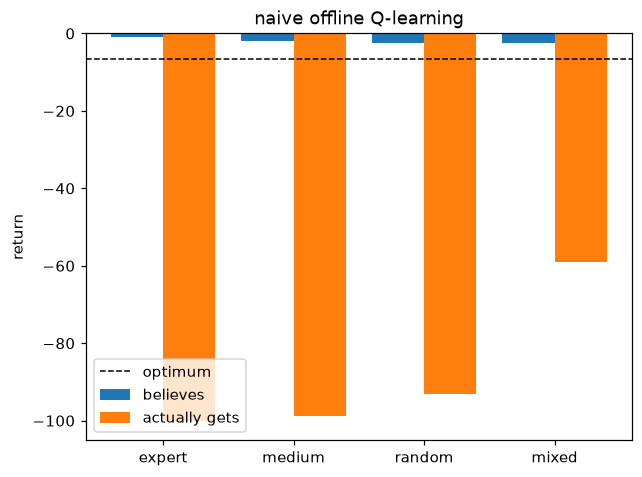

In [5]:
print(f"{'dataset':>8} {'coverage':>9} {'OOS greedy':>11} {'believes':>10} {'actually gets':>14}")
naive = {}
for q, log in logs.items():
    Q = offline_q.train(log)
    naive[q] = offline_q.value_gap(Q, env, log)
    print(f"{q:>8} {log.coverage():>9.3f} {offline_q.out_of_support_fraction(Q, log):>11.2f} {naive[q][0]:>10.2f} {naive[q][1]:>14.2f}")

x = np.arange(len(logs))
plt.bar(x - 0.2, [naive[q][0] for q in logs], 0.4, label="believes")
plt.bar(x + 0.2, [naive[q][1] for q in logs], 0.4, label="actually gets")
plt.axhline(optimal, color="k", ls="--", lw=1, label="optimum")
plt.xticks(x, list(logs)); plt.ylabel("return"); plt.title("naive offline Q-learning"); plt.legend(); plt.show()

The agent's own estimate is the thing that is corrupted, so it cannot be used to detect the corruption.
Compare against an exact evaluation or the behaviour policy's return, never against the agent's own number.

## 3. CQL: push the unseen actions down

CQL adds $\alpha\,[\mathrm{logsumexp}_a Q(s,a) - Q(s, a_{data})]$ to the loss ([`algos/cql_tabular.py:70-81`](../algos/cql_tabular.py)).
Its gradient is $\alpha\,(\mathrm{softmax}(Q(s,\cdot)) - \mathrm{onehot}(a_{data}))$: down on every action, hardest on the one that looks best, up on the one the data took.
With $\alpha = 0$ it is exactly naive offline Q. Medium dataset.

behaviour policy -13.50   optimum -6.54

  alpha  OOS greedy   believes  actually gets
    0.0        0.32      -1.84         -98.73
    0.1        0.18      -4.76         -64.14
    0.5        0.00      -5.82          -6.54
    1.0        0.00      -5.12          -6.54
    2.0        0.00      -3.64          -6.54
    5.0        0.00       2.42          -6.56
   20.0        0.00      61.31         -12.24
  100.0        0.00     536.01         -45.08


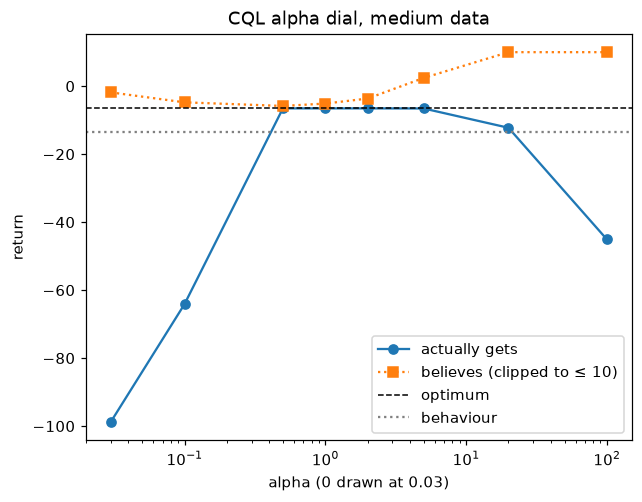

In [6]:
log = logs["medium"]
ALPHAS = (0.0, 0.1, 0.5, 1.0, 2.0, 5.0, 20.0, 100.0)
cql_rows = []
for alpha in ALPHAS:
    Q = cql_tabular.train(log, alpha=alpha)
    believes, gets = offline_q.value_gap(Q, env, log)
    cql_rows.append((alpha, offline_q.out_of_support_fraction(Q, log), believes, gets))
print(f"behaviour policy {behaviour['medium']:.2f}   optimum {optimal:.2f}\n")
print(f"{'alpha':>7} {'OOS greedy':>11} {'believes':>10} {'actually gets':>14}")
for alpha, oos, b, g in cql_rows:
    print(f"{alpha:>7.1f} {oos:>11.2f} {b:>10.2f} {g:>14.2f}")

xs = [max(a, 0.03) for a in ALPHAS]
plt.plot(xs, [r[3] for r in cql_rows], "o-", label="actually gets")
plt.plot(xs, np.clip([r[2] for r in cql_rows], -110, 10), "s:", label="believes (clipped to ≤ 10)")
plt.axhline(optimal, color="k", ls="--", lw=1, label="optimum"); plt.axhline(behaviour["medium"], color="grey", ls=":", label="behaviour")
plt.xscale("log"); plt.xlabel("alpha (0 drawn at 0.03)"); plt.ylabel("return"); plt.legend(); plt.title("CQL alpha dial, medium data"); plt.show()

Watch `believes`. At $\alpha = 0$ it is a lie in the optimistic direction. Around $\alpha = 0.5$ it is honest.
At large $\alpha$ it goes positive on a task where no return can exceed 0: the penalty dominates and Q stops estimating return at all.
The policy it implies can still be good. Never read a conservative Q as a value prediction.

## 4. BCQ: never consider the unseen actions

BCQ restricts the max to actions the log took at $s'$ often enough: at least $\tau$ times as often as the most common one ([`bcq_tabular.py:57-67`](../algos/bcq_tabular.py)).
The tabular version also has to decide what a state the log never acted from is worth (`PESSIMISTIC_VALUE`, line 54).
The ablation separates the two mechanisms.

In [7]:
everything = np.ones((log.n_states, log.n_actions), dtype=bool)
supported = bcq_tabular.admissible_actions(log, threshold=0.0)
print(f"{'max over':>15} {'unseen states get':>19} {'believes':>10} {'actually gets':>14}")
for mask_name, mask in (("all actions", everything), ("supported only", supported)):
    for value_name, value in (("0 (optimistic)", 0.0), ("-100 (pessimistic)", bcq_tabular.PESSIMISTIC_VALUE)):
        Q = bcq_tabular.train(log, allowed=mask, pessimistic_value=value)
        policy = Q.argmax(axis=1) if mask is everything else bcq_tabular.greedy_policy(Q, log, 0.0)
        print(f"{mask_name:>15} {value_name:>19} {float(env.start_distribution @ Q.max(1)):>10.2f} {env.policy_return(policy, GAMMA):>14.2f}")

acted_from = np.zeros(log.n_states, dtype=bool); acted_from[log.states] = True
bootstrapped = log.next_states[~log.terminated]
print(f"\nbootstrapped next-states never acted from: {int((~acted_from[bootstrapped]).sum())} of {len(bootstrapped):,}")

       max over   unseen states get   believes  actually gets


    all actions      0 (optimistic)      -1.84         -98.73


    all actions  -100 (pessimistic)      -1.84         -98.73


 supported only      0 (optimistic)      -6.48          -6.61


 supported only  -100 (pessimistic)      -6.48          -6.61

bootstrapped next-states never acted from: 0 of 18,639


The action constraint does all the work; the pessimism setting changes nothing.
The last line says why: in trajectory data you always act from wherever you landed, unless the episode ended there.
So here extrapolation error is entirely about unseen **actions** at seen states. Pessimism about unseen states would matter for a log of disconnected tuples, such as logged production decisions.

In [8]:
TAUS = (0.0, 0.05, 0.1, 0.3, 0.6, 0.9, 1.0)
visited = log.action_counts().sum(1) > 0
print(f"{'tau':>5} {'admissible per state':>21} {'actually gets':>14}")
bcq_gets = []
for tau in TAUS:
    Q = bcq_tabular.train(log, threshold=tau)
    gets = env.policy_return(bcq_tabular.greedy_policy(Q, log, tau), GAMMA); bcq_gets.append(gets)
    width = bcq_tabular.admissible_actions(log, tau)[visited].sum(1).mean()
    print(f"{tau:>5.2f} {width:>21.2f} {gets:>14.2f}")

  tau  admissible per state  actually gets


 0.00                  4.36          -6.61


 0.05                  4.31          -6.61


 0.10                  4.00          -6.57


 0.30                  2.34          -6.54


 0.60                  1.46          -6.54


 0.90                  1.34          -6.54


 1.00                  1.34          -6.54


## 5. IQL: no max anywhere

IQL learns $V(s)$ by **expectile regression** on the Q values of actions the log took ([`iql_tabular.py:74-78`](../algos/iql_tabular.py)), and the Q target is $r + \gamma V(s')$ (lines 82-88).
At $\tau = 0.5$ the expectile is a mean, and $V$ is the behaviour policy's value. As $\tau \to 1$ it approaches the max over actions *present in the data*.
The policy is extracted by advantage weighting, $\exp(\beta A)$, over seen actions only ([`iql_tabular.py:93-120`](../algos/iql_tabular.py)).

This uses the **random** dataset. On `medium` every setting scores about the same, so the dials have nothing to show.

behaviour policy (random) -32.05   optimum -6.54

  tau  V(start)  actually gets
 0.50    -31.59          -8.75
 0.60    -24.44          -8.71
 0.70    -18.97          -8.80
 0.80    -14.72          -9.32
 0.90    -11.13          -9.46
 0.95     -7.01         -32.50
 0.99     -1.47         -98.51



  beta  actually gets   (tau = 0.9)
   0.0         -99.96
   0.5          -9.59
   1.0          -9.03
   3.0          -9.46
  10.0          -9.93
 100.0          -9.93


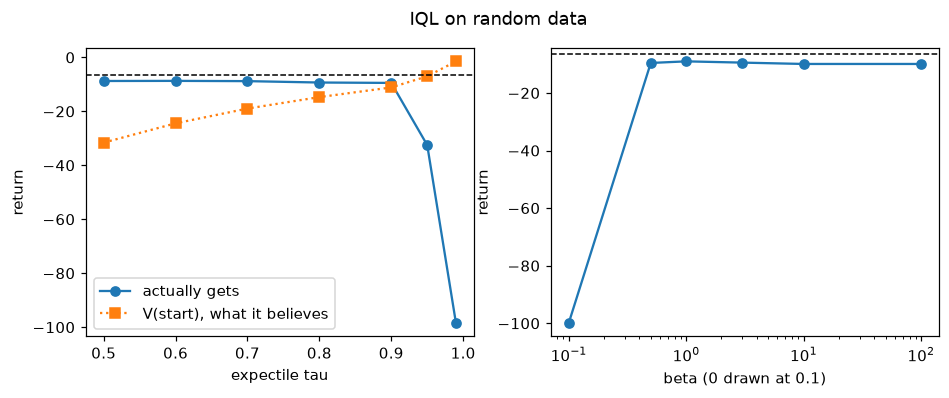

In [9]:
rlog = logs["random"]
EXPECTILES = (0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99)
iql_rows = []
for tau in EXPECTILES:
    Q, V = iql_tabular.train(rlog, expectile=tau)
    iql_rows.append((tau, float(env.start_distribution @ V), env.policy_return(iql_tabular.extract_policy(rlog, Q, V), GAMMA)))
print(f"behaviour policy (random) {behaviour['random']:.2f}   optimum {optimal:.2f}\n")
print(f"{'tau':>5} {'V(start)':>9} {'actually gets':>14}")
for tau, v, g in iql_rows:
    print(f"{tau:>5.2f} {v:>9.2f} {g:>14.2f}")

Q, V = iql_tabular.train(rlog, expectile=0.9)
BETAS = (0.0, 0.5, 1.0, 3.0, 10.0, 100.0)
beta_gets = [env.policy_return(iql_tabular.extract_policy(rlog, Q, V, beta=b), GAMMA) for b in BETAS]
print(f"\n{'beta':>6} {'actually gets':>14}   (tau = 0.9)")
for b, g in zip(BETAS, beta_gets):
    print(f"{b:>6.1f} {g:>14.2f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].plot(EXPECTILES, [r[2] for r in iql_rows], "o-", label="actually gets")
axs[0].plot(EXPECTILES, [r[1] for r in iql_rows], "s:", label="V(start), what it believes")
axs[0].set_xlabel("expectile tau"); axs[0].legend(); axs[0].axhline(optimal, color="k", ls="--", lw=1)
axs[1].plot([max(b, 0.1) for b in BETAS], beta_gets, "o-"); axs[1].set_xscale("log"); axs[1].set_xlabel("beta (0 drawn at 0.1)")
axs[1].axhline(optimal, color="k", ls="--", lw=1)
for ax in axs: ax.set_ylabel("return")
plt.suptitle("IQL on random data"); plt.show()

Look at the top of the expectile range. As $\tau \to 1$ the expectile is carried by one or two transitions per state, $V$ overestimates, and the Q target inherits it.
IQL does not remove the failure mode. It moves it from "unseen actions" to "thinly-seen actions", where a hyperparameter controls it.

## 6. All methods, all four datasets

One setting per method, chosen in the sections above: CQL $\alpha = 1$, BCQ $\tau = 0.3$, IQL $\tau = 0.9$, $\beta = 3$.
**Picking those settings by looking at the true return is cheating.** Offline RL has no validation environment by definition, and this notebook has one only because the track is small enough to solve.
BC is the most-taken action per state.

(17 s)

 dataset  behaviour        BC  naive Q      CQL      BCQ      IQL
  expert      -6.88     -6.54  -100.00    -6.55    -6.55    -6.55
  medium     -13.50     -6.54   -98.73    -6.54    -6.54    -6.54
  random     -32.05    -99.96   -93.07    -9.36    -8.69    -9.46
   mixed     -21.59     -9.04   -59.08    -7.20    -7.29    -7.19


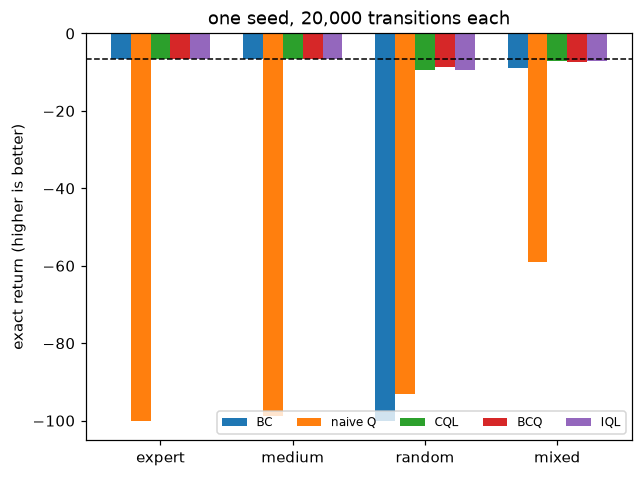

In [10]:
def bc_policy(log):
    counts = log.action_counts()
    policy = counts.argmax(1)
    unseen = counts.sum(1) == 0
    policy[unseen] = np.random.default_rng(0).integers(0, log.n_actions, int(unseen.sum()))
    return policy

t0 = time.time()
methods = {
    "BC": lambda log: bc_policy(log),
    "naive Q": lambda log: offline_q.train(log).argmax(1),
    "CQL": lambda log: cql_tabular.train(log, alpha=1.0).argmax(1),
    "BCQ": lambda log: bcq_tabular.greedy_policy(bcq_tabular.train(log, threshold=0.3), log, 0.3),
    "IQL": lambda log: iql_tabular.extract_policy(log, *iql_tabular.train(log, expectile=0.9)),
}
scores = {(q, m): env.policy_return(fn(log), GAMMA) for q, log in logs.items() for m, fn in methods.items()}
print(f"({time.time() - t0:.0f} s)\n")
print(f"{'dataset':>8} {'behaviour':>10} " + "".join(f"{m:>9}" for m in methods))
for q in logs:
    print(f"{q:>8} {behaviour[q]:>10.2f} " + "".join(f"{scores[q, m]:>9.2f}" for m in methods))

x = np.arange(len(logs)); w = 0.15
for k, m in enumerate(methods):
    plt.bar(x + (k - 2) * w, [scores[q, m] for q in logs], w, label=m)
plt.axhline(optimal, color="k", ls="--", lw=1)
plt.xticks(x, list(logs)); plt.ylabel("exact return (higher is better)"); plt.legend(ncol=5, fontsize=8)
plt.title("one seed, 20,000 transitions each"); plt.show()

## 7. Offline, then online: the handover

Pretrain with CQL ($\alpha = 1$) on the medium log, then run online Q-learning from that table ([`algos/offline_to_online.py:51-112`](../algos/offline_to_online.py)).
Four variants, three seeds, 40,000 online steps, exact evaluation every 5,000:

| variant | what happens after the switch |
| --- | --- |
| scratch | no pretraining; the baseline |
| naive | Q-learning from the pretrained table |
| mixed replay | each online step also replays 4 transitions from the offline log |
| gentle | naive with learning rate 0.02 instead of 0.3 |

(46 s)   CQL after pretraining: -6.54   optimum -6.54

 online steps        scratch         naive  mixed replay        gentle
            0        -100.00         -6.54         -6.54         -6.54
        5,000         -71.79         -6.94         -6.73         -6.54
       10,000         -41.88         -8.93         -8.25         -6.71
       15,000         -47.46         -6.94         -6.57        -29.95
       20,000         -16.53         -6.63         -6.55         -6.80
       25,000         -35.77         -6.85         -6.55         -7.03
       30,000         -13.92         -6.68         -6.61         -6.56
       35,000         -33.22         -6.59         -6.61         -6.80
       40,000         -14.82         -6.57         -6.66         -6.78


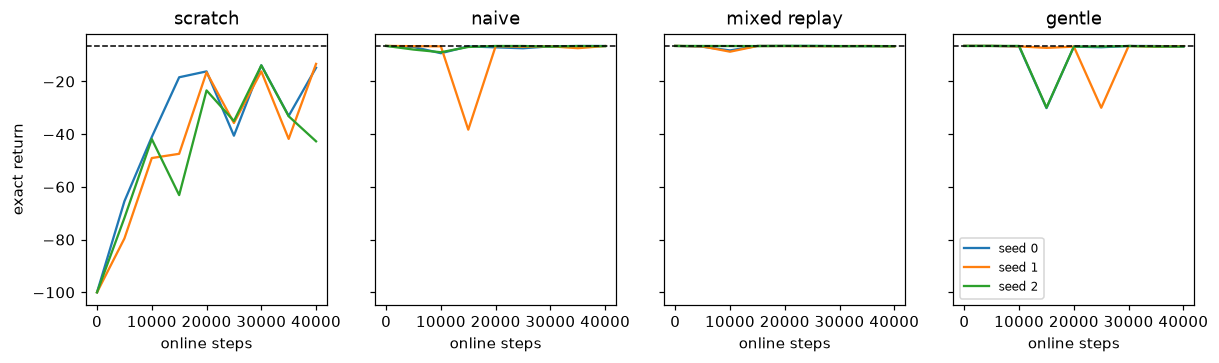

In [11]:
t0 = time.time()
pretrained = cql_tabular.train(log, alpha=1.0, gamma=GAMMA)
pretrained_value = env.policy_return(pretrained.argmax(1), GAMMA)
runs = {"scratch": dict(Q=np.zeros_like(pretrained)), "naive": dict(Q=pretrained),
        "mixed replay": dict(Q=pretrained, dataset=log, replay_batch=4),
        "gentle": dict(Q=pretrained, learning_rate=offline_to_online.GENTLE_LEARNING_RATE)}
curves = {name: [offline_to_online.finetune(env, seed=seed, **kw) for seed in offline_to_online.SEEDS] for name, kw in runs.items()}
print(f"({time.time() - t0:.0f} s)   CQL after pretraining: {pretrained_value:.2f}   optimum {optimal:.2f}\n")

steps = [s for s, _ in curves["scratch"][0]]
print(f"{'online steps':>13} " + "".join(f"{n:>14}" for n in runs))
for i, s in enumerate(steps):
    print(f"{s:>13,} " + "".join(f"{np.median([c[i][1] for c in curves[n]]):>14.2f}" for n in runs))

fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, name in zip(axs, runs):
    for seed, c in enumerate(curves[name]):
        ax.plot(*zip(*c), label=f"seed {seed}")
    ax.axhline(optimal, color="k", ls="--", lw=1); ax.set_title(name); ax.set_xlabel("online steps")
axs[0].set_ylabel("exact return"); axs[-1].legend(fontsize=8); plt.show()

Read each seed, not only the median. A single seed can support whichever conclusion you already held.
An exact evaluation has no measurement noise, but the policy still jumps: one Q entry flipping the argmax in a reachable state can strand the car.

"Gentle" has the deepest dip: its median is −29.95 at 15,000 steps, then it recovers to −6.78. A smaller learning rate was supposed to make the handover safer.
The file records a hypothesis for this, labelled there as **not verified**: a conservative Q is not on the scale of a return, and a small learning rate leaves corrected and uncorrected entries on different scales for longer.
Mixed replay has the shallowest median dip (−8.25), and pretraining on the log beats 40,000 online steps from scratch (−14.82).

## 8. What breaks, and how you would know

| method | symptom | cause |
| --- | --- | --- |
| naive offline Q | works fine and you expected it to fail | rewards ≥ 0 with Q initialised at 0: untouched entries are pessimistic, so the tabular test passes while the deep version is broken |
| CQL | no alpha helps | the log has no good trajectory to stitch; print the behaviour return first |
| CQL | `believes` positive on a −1-per-step task | alpha so large Q is no longer a return |
| BCQ | no better than naive | policy extraction used an unrestricted argmax ([`bcq_tabular.py:113-125`](../algos/bcq_tabular.py)) |
| IQL | identical to BC | expectile near 0.5 |
| IQL | identical to naive offline Q | extraction took an argmax over unseen actions |
| offline → online | fine-tuning slower than scratch | pretrained Q is confidently wrong where the online policy now goes |